# Vision Assist V1 — Clean, Reproducible Workflow

**Purpose:** prepare the ROD dataset, train one proper YOLOv8n baseline, evaluate on validation data, inspect predictions, and save a compact experiment summary.

## Run order

Run cells **1 → 2 → 3 → 4 → 5 → 6** in order. Do not rerun random old cells from the previous notebook.

- Cell 1: environment and GPU check
- Cell 2: prepare dataset and convert polygon labels to bounding boxes
- Cell 3: train the 50-epoch baseline (best checkpoint selected using validation data)
- Cell 4: evaluate on validation data only
- Cell 5: visual inspection on validation examples
- Cell 6: save experiment metadata and metrics locally

**Research hygiene:** the existing baseline has already been evaluated on the test split. Do not use test metrics to tune this new training run. Once model choices are fixed using validation results, use the test split for one final, documented comparison.

This is an experimental prototype, not a safety-grade navigation system.

## 1. Environment and GPU

Enable **GPU** in Kaggle notebook settings before running.

In [1]:
from pathlib import Path
import importlib.util
import subprocess
import sys
import json
import random
import shutil
import time

import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not enabled. In Kaggle, open Notebook Settings > Accelerator > GPU, "
        "then rerun this cell."
    )

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

if importlib.util.find_spec("ultralytics") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "ultralytics", "PyYAML"
    ])

from ultralytics import YOLO
import yaml

print("Ultralytics and YAML ready.")

Python: 3.13.15
PyTorch: 2.11.0+cu128
CUDA: 12.8
GPU 0: Tesla T4
GPU 1: Tesla T4
Ultralytics and YAML ready.


## 2. Prepare the ROD dataset

This uses the ROD dataset attached to this Kaggle notebook. It creates a prepared dataset under `/kaggle/working/rod_detection` and converts polygon annotations to enclosing bounding boxes.

The source dataset is left unchanged. Images are symlinked to avoid copying them.

In [2]:
SOURCE = Path(
    "/kaggle/input/datasets/abtinzandi/"
    "obstacle-detection-dataset/ROD-Dataset/dataset"
)
DATA_DIR = Path("/kaggle/working/rod_detection")
DATA_YAML = Path("/kaggle/working/rod_detection.yaml")
RUNS_DIR = Path("/kaggle/working/vision_assist")

if not SOURCE.exists():
    raise FileNotFoundError(
        f"ROD dataset not found at {SOURCE}. Attach the ROD dataset in Kaggle's Input panel."
    )

CLASS_NAMES = [
    "Bike", "Building", "Car", "Person", "Stairs", "Traffic sign",
    "Electrical Pole", "Road", "Motorcycle", "Dustbin", "Dog", "Manhole",
    "Tree", "Guard rail", "Pedestrian crosswalk", "Truck", "Bus", "Bench",
    "Traffic Cone", "Fire hydrant", "Teraffic Barrel", "Plant Pot",
    "Electrical Box", "Chair", "Bicycle Rack"
]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLITS = ["train", "valid", "test"]

# Recreate only the derived working copy; do not alter SOURCE.
if DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)
DATA_DIR.mkdir(parents=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

summary = {}

for split in SPLITS:
    src_images = SOURCE / split / "images"
    src_labels = SOURCE / split / "labels"
    out_images = DATA_DIR / split / "images"
    out_labels = DATA_DIR / split / "labels"
    out_images.mkdir(parents=True)
    out_labels.mkdir(parents=True)

    if not src_images.is_dir() or not src_labels.is_dir():
        raise FileNotFoundError(f"Missing source images or labels for split: {split}")

    image_files = sorted(
        p for p in src_images.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )
    if not image_files:
        raise RuntimeError(f"No images found for {split}")

    for image_path in image_files:
        (out_images / image_path.name).symlink_to(image_path)

    bbox_count = 0
    polygon_count = 0
    skipped = 0
    label_files = list(src_labels.glob("*.txt"))

    for label_path in label_files:
        output_lines = []
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if not parts:
                continue
            try:
                class_id = int(parts[0])
                coords = [float(x) for x in parts[1:]]
            except (ValueError, OverflowError):
                skipped += 1
                continue

            if not (0 <= class_id < len(CLASS_NAMES)):
                skipped += 1
                continue

            if len(coords) == 4:
                x, y, w, h = coords
                kind = "bbox"
            elif len(coords) >= 6 and len(coords) % 2 == 0:
                xs, ys = coords[0::2], coords[1::2]
                xmin, xmax = min(xs), max(xs)
                ymin, ymax = min(ys), max(ys)
                x, y = (xmin + xmax) / 2, (ymin + ymax) / 2
                w, h = xmax - xmin, ymax - ymin
                kind = "polygon"
            else:
                skipped += 1
                continue

            if (
                not all(0 <= v <= 1 for v in (x, y, w, h))
                or w <= 0 or h <= 0
            ):
                skipped += 1
                continue

            output_lines.append(
                f"{class_id} {x:.6f} {y:.6f} {w:.6f} {h:.6f}"
            )
            if kind == "bbox":
                bbox_count += 1
            else:
                polygon_count += 1

        (out_labels / label_path.name).write_text(
            "\n".join(output_lines) + ("\n" if output_lines else "")
        )

    missing_labels = [
        p.name for p in image_files
        if not (out_labels / f"{p.stem}.txt").exists()
    ]
    if missing_labels:
        raise RuntimeError(
            f"{split}: {len(missing_labels)} images lack label files; "
            f"examples: {missing_labels[:5]}"
        )

    summary[split] = {
        "images": len(image_files),
        "label_files": len(label_files),
        "bbox_annotations_preserved": bbox_count,
        "polygon_annotations_converted": polygon_count,
        "skipped_annotations": skipped,
    }
    print(split.upper(), summary[split])

if sum(v["skipped_annotations"] for v in summary.values()) > 0:
    raise RuntimeError("Some annotations were skipped. Inspect counts before training.")

config = {
    "path": str(DATA_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES,
}
DATA_YAML.write_text(yaml.safe_dump(config, sort_keys=False))

print("\nDataset config:", DATA_YAML)
print("Dataset preparation complete.")

TRAIN {'images': 19186, 'label_files': 19186, 'bbox_annotations_preserved': 28336, 'polygon_annotations_converted': 3915, 'skipped_annotations': 0}
VALID {'images': 3511, 'label_files': 3511, 'bbox_annotations_preserved': 4764, 'polygon_annotations_converted': 808, 'skipped_annotations': 0}
TEST {'images': 1629, 'label_files': 1629, 'bbox_annotations_preserved': 1957, 'polygon_annotations_converted': 415, 'skipped_annotations': 0}

Dataset config: /kaggle/working/rod_detection.yaml
Dataset preparation complete.


## 3. Train one proper baseline

This is the **only training cell** in this clean workflow. It trains for up to 50 epochs and selects `best.pt` using validation performance. Early stopping may stop before 50 epochs if validation stops improving.

If Kaggle's runtime limit interrupts training, use the saved `last.pt` checkpoint to resume rather than starting a duplicate run.

In [3]:
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 8
DEVICE = 0
SEED = 42
RUN_NAME = "rod_yolov8n_50ep"

# Explicit pretrained YOLOv8 Nano baseline.
model = YOLO("yolov8n.pt")

train_start = time.time()
train_result = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=2,
    cache=False,
    amp=True,
    pretrained=True,
    seed=SEED,
    deterministic=True,
    patience=10,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=False,
    save=True,
    save_period=5,
    plots=True,
    val=True,
    verbose=True,
)

RUN_DIR = Path(train_result.save_dir)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"
TRAIN_SECONDS = time.time() - train_start

print("\nTraining finished.")
print("Run directory:", RUN_DIR)
print("Best checkpoint exists:", BEST_WEIGHTS.exists())
print("Last checkpoint exists:", LAST_WEIGHTS.exists())
print(f"Training time: {TRAIN_SECONDS / 60:.1f} minutes")

if not BEST_WEIGHTS.exists():
    raise FileNotFoundError(
        f"Best checkpoint not found at {BEST_WEIGHTS}. Check training output."
    )

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/rod_detection.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rod_yolov8n_50ep, nbs=64, nms=None, opset=None, optimiz

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      1.41G      1.181      1.577      1.506          5        640: 100% ━━━━━━━━━━━━ 2399/2399 12.2it/s 3:170.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 220/220 10.9it/s 20.1s0.1ss
                   all       3511       5572      0.559      0.564      0.555      0.337

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      1.41G      1.262      1.742      1.573          3        640: 100% ━━━━━━━━━━━━ 2399/2399 12.7it/s 3:090.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 220/220 10.8it/s 20.4s0.1ss
                   all       3511       5572      0.612      0.551      0.591      0.375

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      1.41G      1.277      1.763      1.592         15        640: 100% ━━━━━━━━━━━━ 2399/2399 12.9it/s 3:060.1ss
              

## 4. Evaluate the selected checkpoint on validation data

Use validation metrics for development decisions. The test split was already evaluated for the smoke-test baseline, so this cell deliberately uses `split="val"`.

In [4]:
best_model = YOLO(str(BEST_WEIGHTS))
val_metrics = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=2,
    plots=True,
    project=str(RUNS_DIR),
    name=f"{RUN_NAME}_validation",
    exist_ok=False,
)

METRICS = {
    "model": "YOLOv8n",
    "run_name": RUN_NAME,
    "epochs_requested": EPOCHS,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "validation_images": summary["valid"]["images"],
    "validation_mAP50": float(val_metrics.box.map50),
    "validation_mAP50_95": float(val_metrics.box.map),
    "validation_precision": float(val_metrics.box.mp),
    "validation_recall": float(val_metrics.box.mr),
    "training_seconds": float(TRAIN_SECONDS),
    "best_checkpoint": str(BEST_WEIGHTS),
}

print("\nVALIDATION METRICS")
for key, value in METRICS.items():
    print(f"{key}: {value}")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,138,539 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 91.0±71.1 MB/s, size: 57.7 KB)
val: Scanning /kaggle/working/rod_detection/valid/labels.cache... 3511 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3511/3511 1.3Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 439/439 14.8it/s 29.7s0.1ss
                   all       3511       5572      0.874      0.841      0.907      0.726
                  Bike         88         95      0.988      0.899       0.96      0.834
              Building         95        101      0.739      0.881      0.875      0.687
                   Car        557       1003      0.925      0.758      0.888      0.633
                Person        347       1033      0.845      0.758      0.847      0.568
                Stairs    

## 5. Inspect example predictions

These are validation images for qualitative inspection. They are not a substitute for quantitative evaluation.


IMG_23435.jpg: 1 detections
  Electrical Pole: 0.78


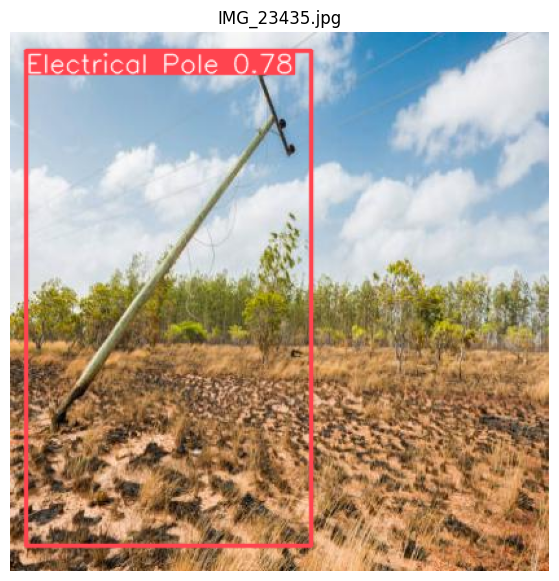


IMG_21272.jpg: 1 detections
  Guard rail: 0.54


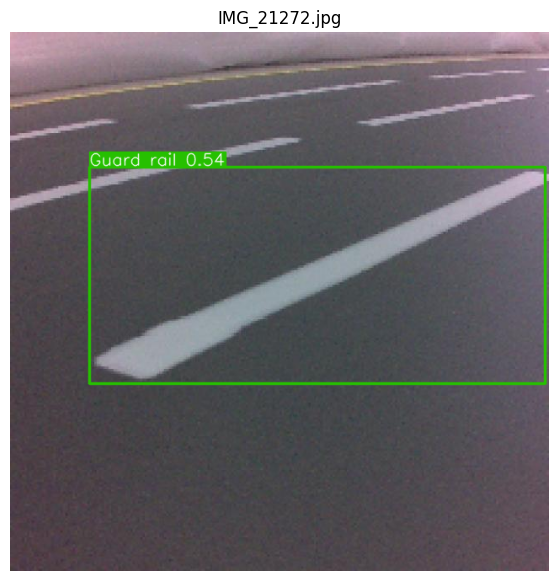


IMG_20918.jpg: 1 detections
  Motorcycle: 0.94


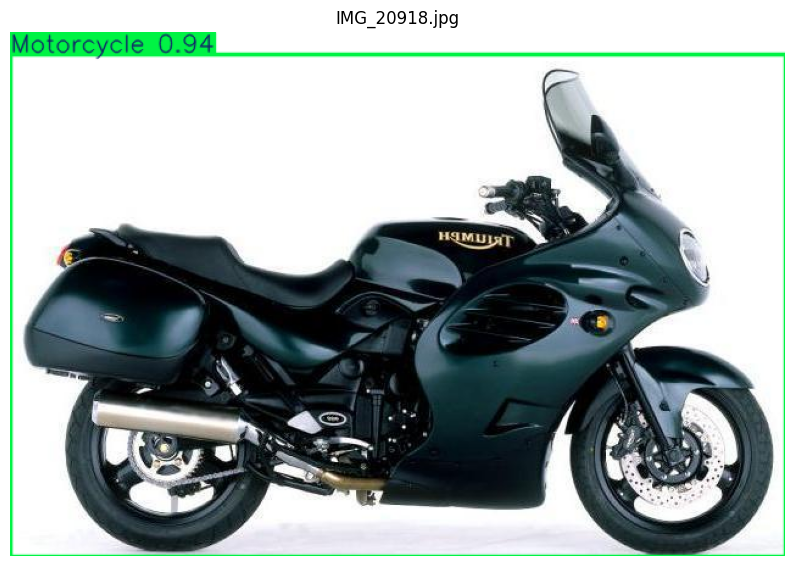


IMG_23853.jpg: 4 detections
  Person: 0.84
  Car: 0.59
  Car: 0.57
  Car: 0.29


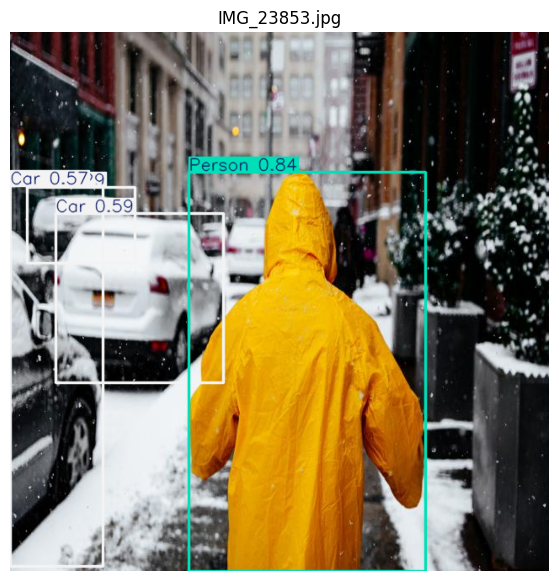


IMG_21942.jpg: 2 detections
  Car: 0.88
  Car: 0.56


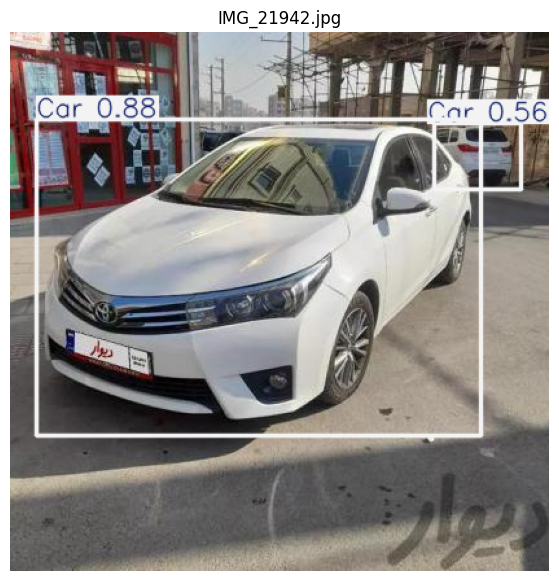


IMG_21819.jpg: 2 detections
  Car: 0.87
  Car: 0.28


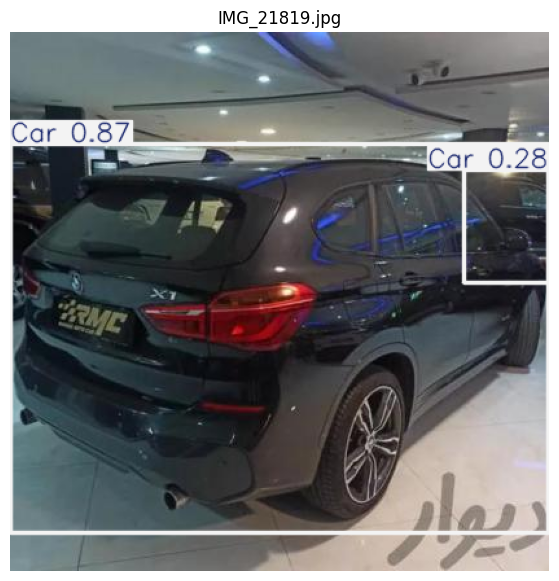

In [5]:
import matplotlib.pyplot as plt

valid_images = sorted(
    p for p in (DATA_DIR / "valid" / "images").iterdir()
    if p.suffix.lower() in IMAGE_EXTS
)
random.seed(SEED)
sample_paths = random.sample(valid_images, min(6, len(valid_images)))

for image_path in sample_paths:
    prediction = best_model.predict(
        source=str(image_path),
        conf=0.25,
        imgsz=IMAGE_SIZE,
        device=DEVICE,
        verbose=False,
    )[0]

    print(f"\n{image_path.name}: {len(prediction.boxes)} detections")
    for box in prediction.boxes:
        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        print(f"  {prediction.names[class_id]}: {confidence:.2f}")

    annotated = prediction.plot()
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[:, :, ::-1])
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

## 6. Save experiment metadata and metrics

This writes a JSON record and copies Ultralytics' result CSV/plots into a compact artifact folder. Upload this folder and the new best checkpoint to GitHub after checking the results.

Do not upload dataset images, label caches, API tokens, or Kaggle secrets.

In [6]:
ARTIFACT_DIR = RUNS_DIR / f"{RUN_NAME}_artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

METRICS["dataset_preparation"] = summary
METRICS["dataset_yaml"] = str(DATA_YAML)
METRICS["checkpoint_size_mb"] = round(
    BEST_WEIGHTS.stat().st_size / (1024 * 1024), 3
)

(ARTIFACT_DIR / "metrics.json").write_text(
    json.dumps(METRICS, indent=2)
)

results_csv = RUN_DIR / "results.csv"
if results_csv.exists():
    shutil.copy2(results_csv, ARTIFACT_DIR / "training_results.csv")

for name in [
    "results.png", "confusion_matrix.png", "confusion_matrix_normalized.png",
    "PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png",
    "labels.jpg", "labels_correlogram.jpg"
]:
    candidate = RUN_DIR / name
    if candidate.exists():
        shutil.copy2(candidate, ARTIFACT_DIR / name)

print("Artifacts saved to:", ARTIFACT_DIR)
print("Checkpoint:", BEST_WEIGHTS)
print("Metrics:", ARTIFACT_DIR / "metrics.json")
print("\nNext: upload BEST_WEIGHTS and ARTIFACT_DIR contents to GitHub.")
print("Do not run test-split evaluation until the final model is selected.")

Artifacts saved to: /kaggle/working/vision_assist/rod_yolov8n_50ep_artifacts
Checkpoint: /kaggle/working/vision_assist/rod_yolov8n_50ep/weights/best.pt
Metrics: /kaggle/working/vision_assist/rod_yolov8n_50ep_artifacts/metrics.json

Next: upload BEST_WEIGHTS and ARTIFACT_DIR contents to GitHub.
Do not run test-split evaluation until the final model is selected.


In [7]:

from pathlib import Path
import os
import subprocess
import shutil

# Paths from your completed 50-epoch training run
RUN_DIR = Path("/kaggle/working/vision_assist/rod_yolov8n_50ep")
ARTIFACT_DIR = Path(
    "/kaggle/working/vision_assist/rod_yolov8n_50ep_artifacts"
)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"

# Check that the required files exist before uploading
assert BEST_WEIGHTS.exists(), f"Missing checkpoint: {BEST_WEIGHTS}"
assert (ARTIFACT_DIR / "metrics.json").exists(), "Missing metrics.json"

# Retrieve the token from Kaggle Secrets without displaying it
try:
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("GITHUB_TOKEN")
except Exception as exc:
    raise RuntimeError(
        "Could not read GITHUB_TOKEN. Check Kaggle Secrets and "
        "enable notebook access to the secret."
    ) from exc

if not token:
    raise RuntimeError("GITHUB_TOKEN is empty.")

# Configure a temporary Git identity and authenticated remote.
# The token is supplied through the environment, not printed.
repo_url = "https://github.com/SudhaMsr/VisionAssist-MVP.git"
env = os.environ.copy()
env["GH_TOKEN_TEMP"] = token

WORK = Path("/kaggle/working/vision_assist/github_upload")
if WORK.exists():
    shutil.rmtree(WORK)

subprocess.run(
    ["git", "clone", repo_url, str(WORK)],
    check=True,
    env={
        **env,
        "GIT_TERMINAL_PROMPT": "0",
        "GIT_CONFIG_COUNT": "1",
        "GIT_CONFIG_KEY_0": "credential.helper",
        "GIT_CONFIG_VALUE_0": (
            "!f() { echo username=x-access-token; "
            "echo password=$GH_TOKEN_TEMP; }; f"
        ),
    },
)

# Copy model checkpoint and experiment artifacts into versioned folders
model_dest = WORK / "models" / "rod_yolov8n_50ep_best.pt"
model_dest.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(BEST_WEIGHTS, model_dest)

artifact_dest = WORK / "results" / "rod_yolov8n_50ep"
artifact_dest.mkdir(parents=True, exist_ok=True)

for src in ARTIFACT_DIR.iterdir():
    if src.is_file():
        shutil.copy2(src, artifact_dest / src.name)

# Stage only these specific files
subprocess.run(
    ["git", "add", "models/rod_yolov8n_50ep_best.pt",
     "results/rod_yolov8n_50ep"],
    cwd=WORK, check=True
)

changed = subprocess.run(
    ["git", "status", "--porcelain"],
    cwd=WORK, check=True, capture_output=True, text=True
).stdout.strip()

if not changed:
    print("No changes to upload; these artifacts may already be committed.")
else:
    subprocess.run(
        ["git", "config", "user.name", "Kaggle Experiment Upload"],
        cwd=WORK, check=True
    )
    subprocess.run(
        ["git", "config", "user.email", "actions@users.noreply.github.com"],
        cwd=WORK, check=True
    )
    subprocess.run(
        ["git", "commit", "-m",
         "Add YOLOv8n 50-epoch validation artifacts"],
        cwd=WORK, check=True
    )

    push_env = env.copy()
    push_env["GIT_TERMINAL_PROMPT"] = "0"
    push_env["GIT_CONFIG_COUNT"] = "1"
    push_env["GIT_CONFIG_KEY_0"] = "credential.helper"
    push_env["GIT_CONFIG_VALUE_0"] = (
        "!f() { echo username=x-access-token; "
        "echo password=$GH_TOKEN_TEMP; }; f"
    )
    subprocess.run(
        ["git", "push", "origin", "HEAD"],
        cwd=WORK, check=True, env=push_env
    )
    print("GitHub upload completed.")

print("Checkpoint:", model_dest)
print("Artifacts:", artifact_dest)
print("Verify the new files in your GitHub repository.")


Cloning into '/kaggle/working/vision_assist/github_upload'...


[main 91c7d42] Add YOLOv8n 50-epoch validation artifacts
 7 files changed, 91 insertions(+)
 create mode 100644 models/rod_yolov8n_50ep_best.pt
 create mode 100644 results/rod_yolov8n_50ep/confusion_matrix.png
 create mode 100644 results/rod_yolov8n_50ep/confusion_matrix_normalized.png
 create mode 100644 results/rod_yolov8n_50ep/labels.jpg
 create mode 100644 results/rod_yolov8n_50ep/metrics.json
 create mode 100644 results/rod_yolov8n_50ep/results.png
 create mode 100644 results/rod_yolov8n_50ep/training_results.csv
GitHub upload completed.
Checkpoint: /kaggle/working/vision_assist/github_upload/models/rod_yolov8n_50ep_best.pt
Artifacts: /kaggle/working/vision_assist/github_upload/results/rod_yolov8n_50ep
Verify the new files in your GitHub repository.


To https://github.com/SudhaMsr/VisionAssist-MVP.git
   6aeab6f..91c7d42  HEAD -> main
